# HDD 07 — Frozen drift monitoring and guarded review

The current detector is promising for temperature spikes and weak for several other controlled deviations. No overall winner or general fault-detection claim is established. Drift monitoring here measures a separate capability and does not repair those blind spots automatically.

**Next question:** can a frozen drift monitor distinguish persistent distribution changes from an unchanged replay, and what review decisions would conservative proxy guards produce?

Monitor four fleet summaries: raw endpoint-temperature median, median E score, median D score, and the share assigned to the largest training partition. River ADWIN receives bounded [0,1] values. No real failure labels or June data are read. A drift signal can mean benign change, data-quality change or fault-like change; it never diagnoses failure.

This implements monitoring and a **review/quarantine simulation only**. It does not implement the proposal's replay-buffer fine-tuning, old-regime regression tests, accepted updates, recovery metrics or rollback. Those require an independently validated update policy.


## 1. Dependencies, paths and frozen upstream identity



In [2]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "pyarrow>=16" "hdbscan>=0.8.40,<0.9" "river==0.26.1" joblib matplotlib tqdm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import json, hashlib, platform, inspect
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from river import drift
from hdbscan.prediction import approximate_predict
from tqdm.auto import tqdm

COMPONENT_ROOT=Path(r'D:/SLIIT/Y4S1/RP/Research/J26-DS-342-/01_component_1_behavioral_drift_genai')
RUN_ID='single_model_q1q2_2021_v1'
ABLATION_ID='representation_ablation_v1_seed42'
SCORE_ID='partition_scoring_v1'
DRIFT_ID='frozen_fleet_drift_v1'
SEED=42

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()

SCORE_OUT=COMPONENT_ROOT/'results'/RUN_ID/SCORE_ID
SCORE_MODELS=COMPONENT_ROOT/'models/trained'/RUN_ID/SCORE_ID
score_complete_path=SCORE_OUT/'scoring_complete.json'
if not score_complete_path.is_file():raise FileNotFoundError(f'Complete Notebook 06 first, or correct paths: {score_complete_path.resolve()}')
score_record=json.loads(score_complete_path.read_text())
assert score_record['analysis_complete'] and score_record['sealed_test_opened'] is False
assert score_record['real_failure_labels_used'] is False
spec_path=SCORE_MODELS/'scoring_specification.json'
assert sha256(spec_path)==score_record['specification_sha256']
spec=json.loads(spec_path.read_text());assert spec['transition_weight']==0
checkpoint=COMPONENT_ROOT/spec['upstream_encoder_checkpoint']
pipeline_path=COMPONENT_ROOT/spec['upstream_partition_pipeline']
assert sha256(checkpoint)==spec['checkpoint_sha256']
assert sha256(pipeline_path)==spec['partition_pipeline_sha256']
assert sha256(SCORE_MODELS/'prototypes.npz')==spec['prototype_sha256']
assert sha256(SCORE_MODELS/'settings.json')==spec['settings_sha256']
ablation_path=COMPONENT_ROOT/'results'/RUN_ID/ABLATION_ID/'representation_ablation_complete.json'
assert sha256(ablation_path)==spec['ablation_complete_sha256']
ablation=json.loads(ablation_path.read_text())
complete_path=COMPONENT_ROOT/'experiments'/RUN_ID/'dataset_complete.json'
assert sha256(complete_path)==ablation['settings']['dataset_complete_sha256']
complete=json.loads(complete_path.read_text());assert complete['status']=='passed'
for relative,digest in complete['working_hashes'].items():assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed dataset: {relative}'
config_path=COMPONENT_ROOT/'config'/f'{RUN_ID}.json';assert sha256(config_path)==complete['config_sha256']
cfg=json.loads(config_path.read_text());FEATURES=cfg['raw_features'];T=cfg['window_days'];TEMP=FEATURES.index('smart_194_raw')
pipeline=joblib.load(pipeline_path)  # Load only your own trusted local model artifacts.
with np.load(SCORE_MODELS/'prototypes.npz') as a:
    centers=a['centers'];radii=a['radii']
assert np.isfinite(radii).all() and (radii>0).all()
OUT=COMPONENT_ROOT/'results'/RUN_ID/DRIFT_ID
DRIFT_MODELS=COMPONENT_ROOT/'models/trained'/RUN_ID/DRIFT_ID
for path in [OUT,DRIFT_MODELS]:path.mkdir(parents=True,exist_ok=True)
print('Verified frozen scoring experiment:',SCORE_ID)
print('River version:',version('river'))


Verified frozen scoring experiment: partition_scoring_v1
River version: 0.26.1


c:\Users\IMAKA\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Declare the stream and control policy
**Natural stream:** one observation per May endpoint date, aggregating only that date's available windows from the fixed development serial list. No serial is silently replaced. Log observed panel fraction and skip detector updates below 80% coverage. There are only 31 natural dates, so this stream is an illustration with limited statistical power.

**Controlled replays:** one observation is a synthetic fleet batch. For each seed, draw May date blocks with replacement for 800 observations. Preserve the within-date cross-drive observations and use the same date draws for every scenario. Introduce a persistent shift at index 300, or a single transient spike there. Reuse exactly computed frozen-model perturbation outputs, not interpolated anomaly scores.

Repeated date blocks are not new operating days, extra independent drives, a realistic continuous physical trajectory or evidence of long-term reliability. Record detection delay in **synthetic batch observations** only. The natural May stream and synthetic replay results are separate.

ADWIN settings are fixed before execution; do not tune them to force a 14-day target. The four monitors are reported individually, not ORed into one statistically calibrated drift detector.

**Proxy guards:** recommend quarantine when at least 10% of observed windows exceed the frozen E/global threshold or at least 5% show an endpoint sector-count increase over seven days. Hold quarantine for ten subsequent batch positions. These are conservative engineering proxies, not failure labels or a validated safe-adaptation rule. Without the proxy, a drift event can only recommend review. Automatic adaptation is always disabled.


In [4]:
SETTINGS={
    'seed':SEED,'replay_seeds':[42,43,44],'replay_observations':800,'change_index':300,
    'adwin_delta':.002,'adwin_clock':1,'adwin_min_window_length':5,'adwin_grace_period':10,
    'minimum_panel_fraction':.8,'quarantine_E_fraction':.10,'quarantine_sector_change_fraction':.05,
    'quarantine_hold_batches':10,'sparse_shift_drive_fraction':.10,'sparse_shift_seed':77,
    'automatic_adaptation':False,'score_specification_sha256':sha256(spec_path),
    'stream_unit':'one synthetic fleet date-block batch; natural stream uses one actual May endpoint date',
    'monitors':['temperature_median','E_median','D_median','dominant_partition_fraction'],
    'scenarios':['unchanged_control','fleet_temperature_plus_2','fleet_temperature_plus_5',
        'fleet_sector_shift','sparse_sector_shift','isolated_temperature_spike'],
}
settings_path=DRIFT_MODELS/'settings.json'
if settings_path.exists() and json.loads(settings_path.read_text())!=SETTINGS:
    raise ValueError('Drift protocol changed. Use a new DRIFT_ID.')
settings_path.write_text(json.dumps(SETTINGS,indent=2))
required={'delta','clock','min_window_length','grace_period'}
if not required.issubset(inspect.signature(drift.ADWIN).parameters):
    raise RuntimeError('Installed River ADWIN API differs; use the declared River version rather than silently changing the experiment.')

def new_monitor():
    return drift.ADWIN(delta=SETTINGS['adwin_delta'],clock=SETTINGS['adwin_clock'],
        min_window_length=SETTINGS['adwin_min_window_length'],grace_period=SETTINGS['adwin_grace_period'])
print('Replay change begins at zero-based index:',SETTINGS['change_index'])
print('Automatic model updates:',SETTINGS['automatic_adaptation'])


Replay change begins at zero-based index: 300
Automatic model updates: False


## 3. Reconstruct and verify frozen E/D values and assignments
Convert embeddings to float64 **before** scaling, matching the corrected Notebook 06 and Notebook 05B. Verify stored E/D tables against saved representations; validate metadata row order and frozen thresholds. Save input hashes for provenance.

The development panel is the already declared split, including serials without every May window. It is not restricted to drives surviving the whole period. Preserve all available rows and report coverage rather than backfilling unavailable observations.


In [5]:
FEATURE_ROOT=COMPONENT_ROOT/'data/features'/RUN_ID
RAW,META,REP,POINTS={},{},{},{}
INPUT_HASHES={}

def remember(path):INPUT_HASHES[str(path.relative_to(COMPONENT_ROOT))]=sha256(path)

def frozen_values(result):
    embedding=np.ascontiguousarray(result['embeddings'],dtype=np.float64)
    z=np.ascontiguousarray(pipeline['pca'].transform(pipeline['scaler'].transform(embedding)),dtype=np.float64)
    labels,_=approximate_predict(pipeline['clusterer'],z)
    D=(np.linalg.norm(z[:,None,:]-centers[None,:,:],axis=2)/radii[None,:]).min(1)
    E=result['last_day_errors'][:,TEMP]
    assert np.isfinite(E).all() and np.isfinite(D).all()
    return np.asarray(E),np.asarray(D),labels.astype(int)

for split in ['train','development']:
    folder=FEATURE_ROOT/ABLATION_ID/'new_encoder'/split
    rep_path=folder/'representations.npz';meta_path=folder/'metadata.parquet'
    with np.load(rep_path) as a:REP[split]={k:a[k] for k in a.files}
    META[split]=pd.read_parquet(meta_path).reset_index(drop=True)
    pd.testing.assert_frame_equal(META[split],pd.read_parquet(FEATURE_ROOT/split/'metadata.parquet').reset_index(drop=True))
    raw_path=FEATURE_ROOT/split/'windows_raw.npz'
    with np.load(raw_path) as a:RAW[split]=a['X'].astype(np.float32)
    E,D,labels=frozen_values(REP[split])
    for detector,expected in [('E',E),('D',D)]:
        path=SCORE_OUT/f'{detector}_global_{split}_scores.csv'
        saved=pd.read_csv(path,parse_dates=['start_date','end_date'])
        pd.testing.assert_frame_equal(saved[['serial_number','start_date','end_date']],META[split][['serial_number','start_date','end_date']],check_dtype=False)
        np.testing.assert_allclose(saved['score'],expected,rtol=1e-6,atol=1e-8)
        np.testing.assert_array_equal(saved['partition_label'],labels)
        expected_flags=expected>spec['thresholds'][detector]['global']
        np.testing.assert_array_equal(saved['is_anomaly_candidate'],expected_flags)
        remember(path)
    POINTS[split]={'E':E,'D':D,'labels':labels,'temperature':RAW[split][:,-1,TEMP]}
    for path in [rep_path,meta_path,raw_path]:remember(path)

splits_path=COMPONENT_ROOT/'data/splits'/f'{RUN_ID}_serials.json'
assert sha256(splits_path)==complete['split_sha256']
panel_ids=set(json.loads(splits_path.read_text())['development'])
assert set(META['development']['serial_number']).issubset(panel_ids)
PANEL_SIZE=len(panel_ids)
assert PANEL_SIZE>0
counts=pd.Series(POINTS['train']['labels']).value_counts()
non_noise=counts[counts.index>=0]
assert len(non_noise)>0
DOMINANT_PARTITION=int(non_noise.index[0])
print('Fixed declared development panel:',PANEL_SIZE,'drives')
print('Observed May endpoint dates:',META['development']['end_date'].nunique())
print('Largest training partition:',DOMINANT_PARTITION,'(no health semantics)')


Fixed declared development panel: 150 drives
Observed May endpoint dates: 31
Largest training partition: 1 (no health semantics)


## 4. Verify the existing perturbation caches and create paired controls
Use cached +2/+5 shifts, the final-day +10 spike, and the paired SMART 197/198 +8 shift. These were computed by the actual frozen encoder in Notebook 06. Check cache identity and byte hashes before use, and reproduce its E/D scores and partition assignments.

The sparse-sector control modifies a fixed 10% of declared panel serials, selected without labels. Other windows retain their original values and scores. This prevents using a fleet-wide perturbation to claim sensitivity to isolated faults. It is still a fault-like controlled scenario, not a physical failure simulator.


In [6]:
ABLATION_MODELS=COMPONENT_ROOT/'models/trained'/RUN_ID/ABLATION_ID
delta_path=ABLATION_MODELS/'change_preprocessing.json'
prep_path=COMPONENT_ROOT/'models/trained'/f'{RUN_ID}_daily_preprocessing.json'
cache_identity=hashlib.sha256((sha256(SCORE_MODELS/'settings.json')+sha256(checkpoint)+sha256(FEATURE_ROOT/'development'/'windows_raw.npz')+sha256(delta_path)+sha256(prep_path)).encode()).hexdigest()
CACHE_NAMES=['temperature_plus_2_last_7_days','temperature_plus_5_last_7_days','temperature_spike_plus_10','sector_197_198_plus_8_last_7_days']
MODIFIED={}

def changed_raw(name):
    x=RAW['development'].copy()
    if name=='temperature_plus_2_last_7_days':x[:,-7:,TEMP]+=2
    elif name=='temperature_plus_5_last_7_days':x[:,-7:,TEMP]+=5
    elif name=='temperature_spike_plus_10':x[:,-1,TEMP]+=10
    elif name=='sector_197_198_plus_8_last_7_days':
        for f in ['smart_197_raw','smart_198_raw']:x[:,-7:,FEATURES.index(f)]+=8
    else:raise ValueError(name)
    return x

SECTORS=[FEATURES.index(f) for f in ['smart_5_raw','smart_197_raw','smart_198_raw']]

def sector_increase(raw):
    return np.any(raw[:,-1,SECTORS]-raw[:,-8,SECTORS]>0,axis=1)

for name in CACHE_NAMES:
    path=SCORE_OUT/'synthetic_cache'/f'{name}.npz';manifest=path.with_suffix('.json')
    if not path.is_file() or not manifest.is_file():raise FileNotFoundError(f'Run all Notebook 06 sensitivity cells. Missing: {path}')
    info=json.loads(manifest.read_text())
    assert info['identity']==cache_identity and info['sha256']==sha256(path), f'Stale perturbation cache: {name}'
    with np.load(path) as a:result={k:a[k] for k in a.files}
    E,D,labels=frozen_values(result)
    for detector,expected in [('E',E),('D',D)]:
        csv_path=SCORE_OUT/f'{name}_{detector}_global.csv'
        saved=pd.read_csv(csv_path,parse_dates=['start_date','end_date'])
        pd.testing.assert_frame_equal(saved[['serial_number','start_date','end_date']],META['development'][['serial_number','start_date','end_date']],check_dtype=False)
        np.testing.assert_allclose(saved['score'],expected,rtol=1e-6,atol=1e-8)
        np.testing.assert_array_equal(saved['partition_label'],labels)
        remember(csv_path)
    raw=changed_raw(name)
    MODIFIED[name]={'E':E,'D':D,'labels':labels,'temperature':raw[:,-1,TEMP],
        'sector_increase':sector_increase(raw)}
    remember(path);remember(manifest)
BASE={**POINTS['development'],'sector_increase':sector_increase(RAW['development'])}
fault_ids=set(np.random.default_rng(SETTINGS['sparse_shift_seed']).choice(np.array(sorted(panel_ids)),
    max(1,int(len(panel_ids)*SETTINGS['sparse_shift_drive_fraction'])),replace=False).tolist())
fault_rows=META['development']['serial_number'].isin(fault_ids).to_numpy()
sparse={key:np.where(fault_rows,MODIFIED['sector_197_198_plus_8_last_7_days'][key],BASE[key]) for key in BASE}
(DRIFT_MODELS/'sparse_control_serials.json').write_text(json.dumps(sorted(fault_ids),indent=2))
print('Verified four cached perturbations. Sparse control serial count:',len(fault_ids))


Verified four cached perturbations. Sparse control serial count: 15


## 5. Build bounded fleet summaries with training-only scaling
For temperature, use the original training endpoint raw median and IQR. For E and D, apply log1p and use training median/IQR. A zero IQR uses q95-minus-median, then 1 if still constant. Map to [0,1] using 0.5 + atan(z)/pi without refitting on later observations.

The partition proportion is already in [0,1]. It monitors the share of the largest training partition, not similarity to a healthy regime. Raw temperature is included as a transparent reference so that a learned monitor does not get credit for shifts that the raw data detects equally well.

No monitor receives failure labels or scenario names. Scenario truth is used only after running detectors to measure controlled delay and explain results.


In [7]:
NORMALISERS={}
for name,values in [('temperature_median',POINTS['train']['temperature']),('E_median',POINTS['train']['E']),('D_median',POINTS['train']['D'])]:
    log=name!='temperature_median'
    v=np.log1p(values) if log else np.asarray(values,dtype=float)
    center=float(np.median(v));scale=float(np.quantile(v,.75)-np.quantile(v,.25));rule='IQR'
    if scale<=1e-12:scale=float(np.quantile(v,.95)-center);rule='q95-minus-median'
    if scale<=1e-12:scale=1.;rule='constant-scale-1'
    NORMALISERS[name]={'log1p':log,'center':center,'scale':scale,'scale_rule':rule}

def bounded(name,value):
    norm=NORMALISERS[name]
    value=np.log1p(value) if norm['log1p'] else value
    return float(.5+np.arctan((value-norm['center'])/norm['scale'])/np.pi)

endpoint_groups=META['development'].groupby('end_date',sort=True).groups

def daily_summary(points):
    rows=[]
    for date,indices in endpoint_groups.items():
        indices=np.asarray(indices)
        observed=META['development'].iloc[indices]['serial_number'].nunique()
        assert observed==len(indices), 'Duplicate serial on one endpoint date.'
        median_temp=float(np.median(points['temperature'][indices]))
        median_e=float(np.median(points['E'][indices]));median_d=float(np.median(points['D'][indices]))
        e_fraction=float((points['E'][indices]>spec['thresholds']['E']['global']).mean())
        sector_fraction=float(points['sector_increase'][indices].mean())
        row={'source_date':pd.Timestamp(date),'panel_windows':len(indices),'panel_fraction':observed/PANEL_SIZE,
            'temperature_raw_median':median_temp,'E_raw_median':median_e,'D_raw_median':median_d,
            'E_alert_fraction':e_fraction,'sector_increase_fraction':sector_fraction,
            'temperature_median':bounded('temperature_median',median_temp),
            'E_median':bounded('E_median',median_e),'D_median':bounded('D_median',median_d),
            'dominant_partition_fraction':float((points['labels'][indices]==DOMINANT_PARTITION).mean())}
        rows.append(row)
    table=pd.DataFrame(rows)
    assert np.isfinite(table[SETTINGS['monitors']].to_numpy()).all()
    assert table[SETTINGS['monitors']].ge(0).all().all() and table[SETTINGS['monitors']].le(1).all().all()
    return table

DAILY={'unchanged':daily_summary(BASE),
    'temperature_plus_2':daily_summary(MODIFIED['temperature_plus_2_last_7_days']),
    'temperature_plus_5':daily_summary(MODIFIED['temperature_plus_5_last_7_days']),
    'sector_fleet':daily_summary(MODIFIED['sector_197_198_plus_8_last_7_days']),
    'sector_sparse':daily_summary(sparse),'temperature_spike':daily_summary(MODIFIED['temperature_spike_plus_10'])}
for name,table in DAILY.items():table.to_csv(OUT/f'date_blocks_{name}.csv',index=False)
(DRIFT_MODELS/'monitor_normalisation.json').write_text(json.dumps(NORMALISERS,indent=2))
display(DAILY['unchanged'][['source_date','panel_windows','panel_fraction','E_alert_fraction','sector_increase_fraction']])


,source_date,panel_windows,panel_fraction,E_alert_fraction,sector_increase_fraction
0,2021-05-01,148,0.986667,0.000000,0.0
1,2021-05-02,148,0.986667,0.000000,0.0
2,2021-05-03,148,0.986667,0.000000,0.0
3,2021-05-04,148,0.986667,0.033784,0.0
4,2021-05-05,150,1.000000,0.026667,0.0
5,2021-05-06,150,1.000000,0.006667,0.0
6,2021-05-07,150,1.000000,0.006667,0.0
7,2021-05-08,150,1.000000,0.000000,0.0
8,2021-05-09,150,1.000000,0.000000,0.0
9,2021-05-10,150,1.000000,0.000000,0.0


## 6. Run ADWIN and proxy review guards
Each monitor is an independent ADWIN instance, updated in stream order. A data-quality skip does not update it. River internally resets its adaptive detection state after an alarm; the underlying encoder, partition, scoring thresholds and normalisation remain frozen.

The guard only recommends quarantine/review. Its triggers do not establish failure, safety or an acceptable new normal. An unblocked drift alarm is `review_distribution_change`, never `adapt_model`. Record every decision and its observed reasons.

The natural May stream is short and already inspected during development. Report its alarms descriptively; there is no labelled natural drift truth and no claim of real false-alarm rate.


In [8]:
def run_stream(table):
    monitors={name:new_monitor() for name in SETTINGS['monitors']}
    trace=[];events=[];quarantine_until=-1
    for step,row in table.reset_index(drop=True).iterrows():
        quality_ok=float(row['panel_fraction'])>=SETTINGS['minimum_panel_fraction']
        reasons=[]
        if row['E_alert_fraction']>=SETTINGS['quarantine_E_fraction']:reasons.append('high_E_alert_fraction')
        if row['sector_increase_fraction']>=SETTINGS['quarantine_sector_change_fraction']:reasons.append('sector_increase_proxy')
        if not quality_ok:reasons.append('low_panel_coverage')
        if reasons:quarantine_until=max(quarantine_until,step+SETTINGS['quarantine_hold_batches'])
        quarantined=step<=quarantine_until
        for name,monitor in monitors.items():
            value=float(row[name]);assert np.isfinite(value) and 0<=value<=1
            if quality_ok:monitor.update(value)
            alarm=bool(quality_ok and monitor.drift_detected)
            decision=('quarantine_review' if quarantined else 'review_distribution_change') if alarm else ('quarantine_hold' if quarantined else 'monitor')
            output={'step':int(step),'source_date':row['source_date'],'monitor':name,'value':value,
                'updated':quality_ok,'adwin_width':float(monitor.width),'drift_detected':alarm,
                'quarantine_active':bool(quarantined),'guard_reasons':';'.join(reasons),
                'decision':decision,'model_update_performed':False}
            trace.append(output)
            if alarm:events.append(output.copy())
    columns=['step','source_date','monitor','value','updated','adwin_width','drift_detected','quarantine_active','guard_reasons','decision','model_update_performed']
    return pd.DataFrame(trace,columns=columns),pd.DataFrame(events,columns=columns)

natural_trace,natural_events=run_stream(DAILY['unchanged'])
natural_trace.to_csv(OUT/'natural_May_trace.csv',index=False);natural_events.to_csv(OUT/'natural_May_events.csv',index=False)
print('Natural May endpoints:',len(DAILY['unchanged']),'| drift observations are daily fleet summaries.')
print('Observed natural-stream alarms:',len(natural_events),'| no drift truth is assumed.')
print('Natural May is too short to establish long-term detection or alarm guarantees.')


Natural May endpoints: 31 | drift observations are daily fleet summaries.
Observed natural-stream alarms: 0 | no drift truth is assumed.
Natural May is too short to establish long-term detection or alarm guarantees.


## 7. Controlled, paired replay scenarios
Each seed uses identical sampled date-block indices across scenarios. Persistent conditions replace every post-change block, the sparse condition replaces only the predeclared serial subset before aggregation, and the isolated spike replaces exactly one block.

Replaying cached modified windows avoids approximating a nonlinear model by interpolating its scores. It does not turn independently perturbed windows into a physically coherent long-term history. Even the imposed persistent shift remains a controlled replay experiment.

Report alarms before the imposed change, first alarm at/after it, censoring if undetected, and alarms in the unchanged replay. For the isolated spike, do not label an alarm as successful detection of persistent drift. Delays below are batch observations, not days.


In [9]:
SCENARIOS={
    'unchanged_control':('unchanged','none'),
    'fleet_temperature_plus_2':('temperature_plus_2','persistent'),
    'fleet_temperature_plus_5':('temperature_plus_5','persistent'),
    'fleet_sector_shift':('sector_fleet','persistent'),
    'sparse_sector_shift':('sector_sparse','persistent'),
    'isolated_temperature_spike':('temperature_spike','transient'),
}
N=SETTINGS['replay_observations'];CHANGE=SETTINGS['change_index']
assert 0<CHANGE<N
all_metrics=[];all_events=[];EXAMPLE_TRACE={};all_traces=[]
for seed in SETTINGS['replay_seeds']:
    indices=np.random.default_rng(seed).integers(0,len(DAILY['unchanged']),size=N)
    for scenario,(condition,kind) in SCENARIOS.items():
        replay=DAILY['unchanged'].iloc[indices].reset_index(drop=True).copy()
        if kind=='persistent':
            replay=pd.concat([DAILY['unchanged'].iloc[indices[:CHANGE]],DAILY[condition].iloc[indices[CHANGE:]]],ignore_index=True)
        elif kind=='transient':
            replay=pd.concat([DAILY['unchanged'].iloc[indices[:CHANGE]],DAILY[condition].iloc[indices[[CHANGE]]],DAILY['unchanged'].iloc[indices[CHANGE+1:]]],ignore_index=True)
        trace,events=run_stream(replay)
        trace['scenario']=scenario;trace['seed']=seed;events['scenario']=scenario;events['seed']=seed
        all_traces.append(trace);all_events.append(events)
        if seed==SETTINGS['replay_seeds'][0]:EXAMPLE_TRACE[scenario]=trace
        replay.to_csv(OUT/f'replay_inputs_{scenario}_seed{seed}.csv',index=False)
        for name in SETTINGS['monitors']:
            part=trace.loc[trace['monitor'].eq(name)]
            alarms=part.loc[part['drift_detected'],'step'].to_numpy(dtype=int)
            post=alarms[alarms>=CHANGE]
            first=int(post[0]) if len(post) else None
            persistent=kind=='persistent'
            all_metrics.append({'scenario':scenario,'kind':kind,'seed':seed,'monitor':name,
                'observations':N,'updated_observations':int(part['updated'].sum()),
                'prechange_alarms':int((alarms<CHANGE).sum()),'total_alarms':len(alarms),
                'first_postchange_alarm':first,
                'persistent_shift_detected':bool(persistent and first is not None),
                'persistent_delay_batches':first-CHANGE+1 if persistent and first is not None else None,
                'delay_censored':bool(persistent and first is None),
                'observed_postchange_batches':N-CHANGE if persistent else None,
                'unchanged_alarms_per_1000_updates':1000*len(alarms)/part['updated'].sum() if kind=='none' and part['updated'].any() else None,
                'quarantined_batch_fraction':float(part['quarantine_active'].mean()),
                'automatic_model_updates':0})
metrics=pd.DataFrame(all_metrics)
metrics.to_csv(OUT/'replay_metrics_by_seed.csv',index=False)
traces=pd.concat(all_traces,ignore_index=True);events=pd.concat(all_events,ignore_index=True)
traces.to_csv(OUT/'all_replay_traces.csv',index=False);events.to_csv(OUT/'all_replay_events.csv',index=False)
summary=metrics.groupby(['scenario','kind','monitor'],dropna=False).agg(
    runs=('seed','size'),persistent_detections=('persistent_shift_detected','sum'),
    censored_runs=('delay_censored','sum'),median_detected_delay_batches=('persistent_delay_batches','median'),
    minimum_detected_delay_batches=('persistent_delay_batches','min'),
    maximum_detected_delay_batches=('persistent_delay_batches','max'),
    mean_prechange_alarms=('prechange_alarms','mean'),mean_total_alarms=('total_alarms','mean'),
    mean_unchanged_alarms_per_1000_updates=('unchanged_alarms_per_1000_updates','mean'),
    mean_quarantined_fraction=('quarantined_batch_fraction','mean')).reset_index()
summary.to_csv(OUT/'replay_summary.csv',index=False)
display(summary)
print('Delay medians include detected runs only. Always report censored_runs alongside them.')


C:\Users\IMAKA\AppData\Local\Temp\ipykernel_1344\22348839.py:44: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  traces=pd.concat(all_traces,ignore_index=True);events=pd.concat(all_events,ignore_index=True)


,scenario,kind,monitor,runs,persistent_detections,censored_runs,median_detected_delay_batches,minimum_detected_delay_batches,maximum_detected_delay_batches,mean_prechange_alarms,mean_total_alarms,mean_unchanged_alarms_per_1000_updates,mean_quarantined_fraction
0,fleet_sector_shift,persistent,D_median,3,3,0,46.0,46.0,46.0,0.0,1.000000,NaN,0.62500
1,fleet_sector_shift,persistent,E_median,3,3,0,30.0,30.0,30.0,0.0,1.000000,NaN,0.62500
2,fleet_sector_shift,persistent,dominant_partition_fraction,3,3,0,16.0,16.0,16.0,0.0,1.000000,NaN,0.62500
3,fleet_sector_shift,persistent,temperature_median,3,0,3,NaN,NaN,NaN,0.0,0.000000,NaN,0.62500
4,fleet_temperature_plus_2,persistent,D_median,3,0,3,NaN,NaN,NaN,0.0,0.000000,NaN,0.00000
5,fleet_temperature_plus_2,persistent,E_median,3,0,3,NaN,NaN,NaN,0.0,0.000000,NaN,0.00000
6,fleet_temperature_plus_2,persistent,dominant_partition_fraction,3,0,3,NaN,NaN,NaN,0.0,0.000000,NaN,0.00000
7,fleet_temperature_plus_2,persistent,temperature_median,3,3,0,152.0,135.0,155.0,0.0,1.000000,NaN,0.00000
8,fleet_temperature_plus_5,persistent,D_median,3,0,3,NaN,NaN,NaN,0.0,0.000000,NaN,0.00000
9,fleet_temperature_plus_5,persistent,E_median,3,3,0,72.0,68.0,74.0,0.0,1.000000,NaN,0.00000


Delay medians include detected runs only. Always report censored_runs alongside them.


## 8. Review guard behaviour and plot examples
Examine whether the sector-increase proxy blocks update review during fault-like shifts, whether the one-batch spike holds quarantine, and whether persistent temperature shifts are detectable through raw temperature or learned signals. A guard can also block legitimate behaviour; do not describe it as a validated fault classifier.

Do not infer failure-detection quality from the drift metrics. A sparse fault-like change may correctly produce no fleet-wide drift alarm while still requiring individual-drive anomaly detection. The sector sensitivity gap in Notebook 06 remains an outstanding issue.


,scenario,monitor,decision,alarm_count
0,fleet_sector_shift,D_median,quarantine_review,3
1,fleet_sector_shift,E_median,quarantine_review,3
2,fleet_sector_shift,dominant_partition_fraction,quarantine_review,3
3,fleet_temperature_plus_2,temperature_median,review_distribution_change,3
4,fleet_temperature_plus_5,E_median,review_distribution_change,3
5,fleet_temperature_plus_5,dominant_partition_fraction,review_distribution_change,1
6,fleet_temperature_plus_5,temperature_median,review_distribution_change,3
7,sparse_sector_shift,D_median,quarantine_review,3
8,sparse_sector_shift,dominant_partition_fraction,quarantine_review,3


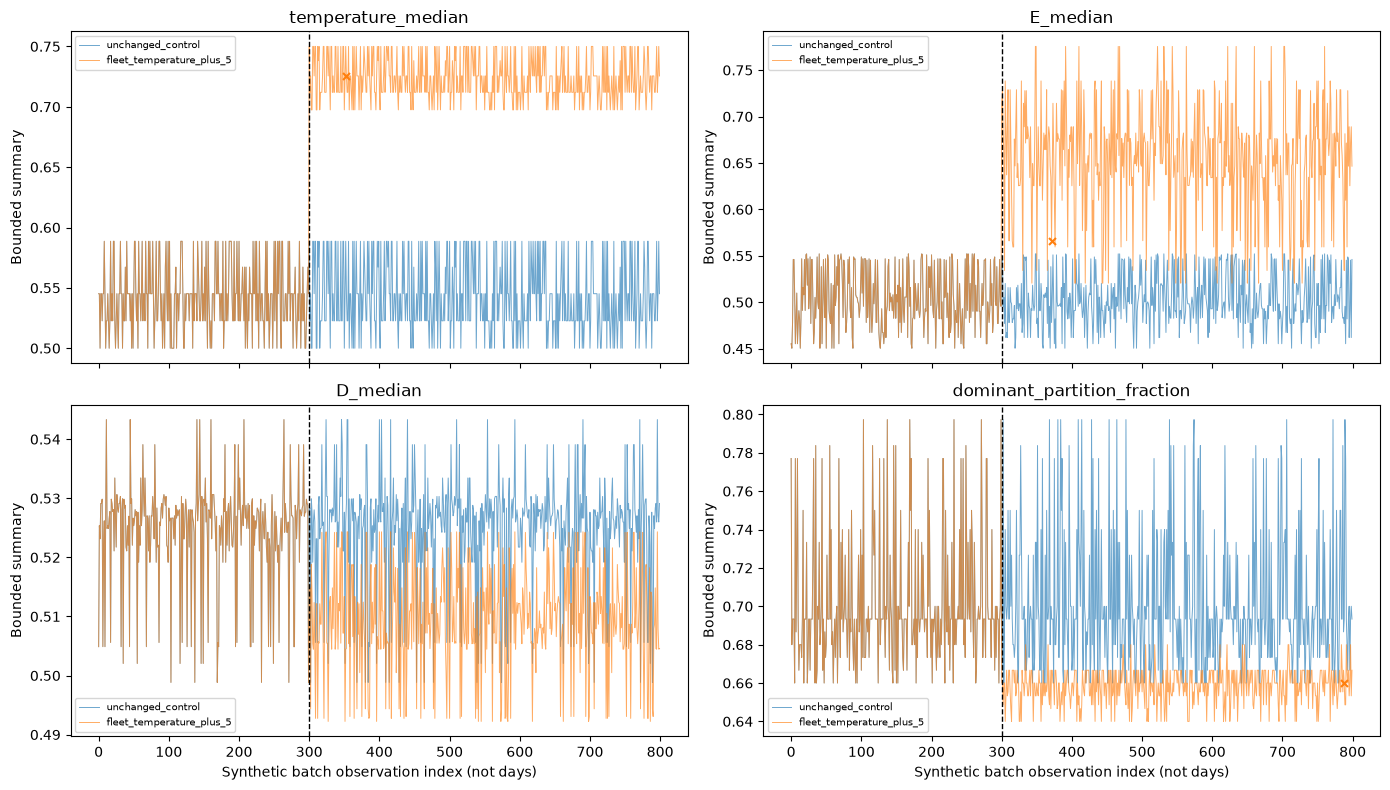

No model update, fine-tuning or rollback was performed in any scenario.


In [10]:
decision_summary=events.groupby(['scenario','monitor','decision']).size().rename('alarm_count').reset_index()
decision_summary.to_csv(OUT/'alarm_review_decisions.csv',index=False)
display(decision_summary)
fig,axes=plt.subplots(2,2,figsize=(14,8),sharex=True)
for ax,name in zip(axes.flat,SETTINGS['monitors']):
    for scenario in ['unchanged_control','fleet_temperature_plus_5']:
        part=EXAMPLE_TRACE[scenario].loc[EXAMPLE_TRACE[scenario]['monitor'].eq(name)]
        ax.plot(part['step'],part['value'],alpha=.65,linewidth=.7,label=scenario)
        alarms=part.loc[part['drift_detected']]
        ax.scatter(alarms['step'],alarms['value'],s=25,marker='x')
    ax.axvline(CHANGE,color='black',linestyle='--',linewidth=1)
    ax.set_title(name);ax.set_ylabel('Bounded summary');ax.legend(fontsize=7)
for ax in axes[-1]:ax.set_xlabel('Synthetic batch observation index (not days)')
fig.tight_layout();fig.savefig(OUT/'controlled_temperature_shift_example.png',dpi=180,bbox_inches='tight');plt.show()
print('No model update, fine-tuning or rollback was performed in any scenario.')


## 9. Verify frozen behaviour and save the experiment
Confirm all learned artifacts are byte-identical, all monitored values are bounded, every replay has the declared length, and no updates occurred. Save the monitor settings and normalisation for review, not a deployed adaptive model.

Completion does not establish a winning anomaly detector or a safe update rule. The next substantive work is to review these controlled results, address sector-count sensitivity, choose/freeze a scoring candidate, and evaluate a quarantined update/replay/rollback policy under a separately recorded protocol. Independent longer-horizon validation, more HDD models and neural seeds, and final failure-based evaluation remain outstanding.


In [11]:
assert traces['model_update_performed'].eq(False).all()
assert traces['value'].between(0,1).all()
expected_runs=len(SETTINGS['replay_seeds'])*len(SCENARIOS)
assert traces.groupby(['scenario','seed','monitor']).size().eq(N).all()
assert metrics.groupby(['scenario','seed']).size().eq(len(SETTINGS['monitors'])).all()
assert sha256(checkpoint)==spec['checkpoint_sha256']
assert sha256(pipeline_path)==spec['partition_pipeline_sha256']
assert sha256(spec_path)==score_record['specification_sha256']
assert sha256(SCORE_MODELS/'prototypes.npz')==spec['prototype_sha256']
for relative,digest in INPUT_HASHES.items():assert sha256(COMPONENT_ROOT/relative)==digest, f'Input changed during analysis: {relative}'
record={'created_utc':datetime.now(timezone.utc).isoformat(),'analysis_complete':True,'run_id':RUN_ID,'drift_id':DRIFT_ID,
    'settings':SETTINGS,'normalisation':NORMALISERS,'input_hashes':INPUT_HASHES,
    'largest_training_partition':DOMINANT_PARTITION,'declared_panel_size':PANEL_SIZE,
    'natural_stream_dates':len(DAILY['unchanged']),'replay_runs':expected_runs,
    'real_failure_labels_used':False,'sealed_test_opened':False,'automatic_model_updates':0,
    'adaptation_validated':False,'real_day_detection_delay_established':False,
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'river':version('river')},
    'limitations':['controlled date-block replays are not independent new operating days','only 31 natural May endpoints',
        'sequential development already inspected','one HDD model and encoder seed','fleet summaries may miss sparse faults',
        'proxy quarantine guards are not validated fault labels','drift can be benign or fault-like',
        'no neural update/replay-buffer acceptance/rollback or recovery evaluation','sector sensitivity remains unresolved']}
(OUT/'drift_monitoring_complete.json').write_text(json.dumps(record,indent=2,allow_nan=False))
print('NOTEBOOK 07 COMPLETE — frozen drift monitoring and guarded-review simulations saved.')
print('Automatic model updates: 0')
print('Results:',OUT)
print('Share replay_summary.csv, alarm_review_decisions.csv and the saved notebook outputs.')


NOTEBOOK 07 COMPLETE — frozen drift monitoring and guarded-review simulations saved.
Automatic model updates: 0
Results: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\results\single_model_q1q2_2021_v1\frozen_fleet_drift_v1
Share replay_summary.csv, alarm_review_decisions.csv and the saved notebook outputs.
